# Original YOLOv1 (Darknet/C) — Hocmay Dataset
**Paper:** *You Only Look Once: Unified, Real-Time Object Detection* (CVPR 2016)

**Dataset:** Hocmay — bike, car, cat, cellphone, dog, person (6 classes)

**Pretrained:** ImageNet backbone (`extraction.conv.weights`) for better mAP

Go to `Runtime → Change runtime type → T4 GPU` before running.

## Install Dependencies

In [1]:
!sudo apt update -q
!sudo apt install -y -q libopencv-dev python3-opencv pkg-config

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:8 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,482 kB]
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Get:11 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,959 kB]
Get:12 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [3,844 kB]
Hit:13 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubu

## Clone & Build Darknet

In [2]:
%cd /content
!rm -rf darknet
!git clone https://github.com/pjreddie/darknet.git
%cd darknet

# Enable GPU + OpenCV
!sed -i 's/GPU=0/GPU=1/' Makefile
!sed -i 's/OPENCV=0/OPENCV=1/' Makefile
!sed -i 's/CUDNN=1/CUDNN=0/' Makefile

# Fix OpenCV 4+ compatibility
!sed -i 's/pkg-config --cflags opencv/pkg-config --cflags opencv4/g' Makefile
!sed -i 's/pkg-config --libs opencv/pkg-config --libs opencv4/g' Makefile
!sed -i 's/COMMON+= -DOPENCV/COMMON+= -DOPENCV -I\/usr\/include\/opencv4/g' Makefile
!sed -i '/ifeq ($(OPENCV), 1)/a LDFLAGS+= -lopencv_core -lopencv_imgproc -lopencv_highgui -lopencv_videoio -lopencv_imgcodecs' Makefile
!sed -i '1i #include "opencv2/imgproc/imgproc_c.h"' src/image_opencv.cpp
!sed -i '1i #include "opencv2/highgui/highgui_c.h"' src/image_opencv.cpp
!sed -i '1i #include "opencv2/videoio/videoio_c.h"' src/image_opencv.cpp
!sed -i 's/IplImage ipl = m;/IplImage ipl = cvIplImage(m);/g' src/image_opencv.cpp
!sed -i 's/CV_CAP_PROP_FRAME_WIDTH/cv::CAP_PROP_FRAME_WIDTH/g' src/image_opencv.cpp
!sed -i 's/CV_CAP_PROP_FRAME_HEIGHT/cv::CAP_PROP_FRAME_HEIGHT/g' src/image_opencv.cpp
!sed -i 's/CV_CAP_PROP_FPS/cv::CAP_PROP_FPS/g' src/image_opencv.cpp
!sed -i 's/ARCH= -gencode arch=compute_30,code=sm_30/ARCH= -gencode arch=compute_60,code=sm_60/g' Makefile
!sed -i 's/-gencode arch=compute_35,code=sm_35//g' Makefile

!make -j4 2>&1 | tail -3
print('Darknet build complete!')

/content
Cloning into 'darknet'...
remote: Enumerating objects: 5955, done.
remote: Total 5955 (delta 0), reused 0 (delta 0), pack-reused 5955 (from 1)
Receiving objects: 100% (5955/5955), 6.37 MiB | 32.31 MiB/s, done.
Resolving deltas: 100% (3932/3932), done.
/content/darknet
gcc -Wall -Wno-unused-result -Wno-unknown-pragmas -Wfatal-errors -fPIC -Ofast -DOPENCV -DGPU -shared obj/gemm.o obj/utils.o obj/cuda.o obj/deconvolutional_layer.o obj/convolutional_layer.o obj/list.o obj/image.o obj/activations.o obj/im2col.o obj/col2im.o obj/blas.o obj/crop_layer.o obj/dropout_layer.o obj/maxpool_layer.o obj/softmax_layer.o obj/data.o obj/matrix.o obj/network.o obj/connected_layer.o obj/cost_layer.o obj/parser.o obj/option_list.o obj/detection_layer.o obj/route_layer.o obj/upsample_layer.o obj/box.o obj/normalization_layer.o obj/avgpool_layer.o obj/layer.o obj/local_layer.o obj/shortcut_layer.o obj/logistic_layer.o obj/activation_layer.o obj/rnn_layer.o obj/gru_layer.o obj/crnn_layer.o obj/demo.

## Download Hocmay Dataset (Darknet format)

In [3]:
%cd /content/darknet
!pip install roboflow -q

from roboflow import Roboflow
import os, yaml

# yolov5 format — images/ and labels/ in separate folders (confirmed working in Notebook 2)
rf = Roboflow(api_key="LU1MoCYnMoh724D0wFsk")
project = rf.workspace("suyogs-workspace-voqgn").project("hocmay1-39isr")
version  = project.version(1)
dataset  = version.download("yolov5")

hocmay_dir = dataset.location   # /content/darknet/hocmay1-1
print(f'Dataset at: {hocmay_dir}')

# Read class info from data.yaml
with open(f'{hocmay_dir}/data.yaml') as f:
    meta = yaml.safe_load(f)
classnames  = meta['names']
num_classes = int(meta['nc'])
print(f'Classes ({num_classes}): {classnames}')

# ── Rename to photo0, photo1... (removes special-char filenames that crashed Notebook 1)
def rename_split(split):
    img_dir = f'{hocmay_dir}/{split}/images/'
    lbl_dir = f'{hocmay_dir}/{split}/labels/'
    if not os.path.exists(img_dir):
        print(f'{split}: not found, skipping'); return
    images = sorted([f for f in os.listdir(img_dir)
                     if f.lower().endswith(('.jpg','.jpeg','.png'))])
    for i, old in enumerate(images):
        ext = os.path.splitext(old)[1]
        new = f'photo{i}'
        os.rename(img_dir + old, img_dir + new + ext)
        old_lbl = os.path.splitext(old)[0] + '.txt'
        if os.path.exists(lbl_dir + old_lbl):
            os.rename(lbl_dir + old_lbl, lbl_dir + new + '.txt')
    print(f'{split}: renamed {len(images)} pairs')

rename_split('train')
rename_split('valid')

# ── Manifest files
def create_manifest(split):
    img_dir = f'{hocmay_dir}/{split}/images'
    imgs = sorted([os.path.join(img_dir, f)
                   for f in os.listdir(img_dir) if f.lower().endswith('.jpg')])
    manifest = f'{img_dir}/manifest.txt'
    with open(manifest, 'w') as f:
        f.write('\n'.join(imgs) + '\n')
    return manifest

train_manifest = create_manifest('train')
valid_manifest = create_manifest('valid')

# Strip any trailing whitespace / CRLF from manifests (fix from Notebook 2 cell-13)
!sed -i 's/[[:space:]]*$//' {train_manifest}
!sed -i 's/\r//g' {train_manifest}
!sed -i 's/[[:space:]]*$//' {valid_manifest}
!sed -i 's/\r//g' {valid_manifest}
print(f'train manifest: {train_manifest}')
print(f'valid manifest: {valid_manifest}')

# ── obj.names
names_path = f'{hocmay_dir}/train/obj.names'
with open(names_path, 'w') as f:
    f.write('\n'.join(classnames) + '\n')

# ── hocmay1-1.data
os.makedirs('backup', exist_ok=True)
with open('cfg/hocmay1-1.data', 'w') as f:
    f.write(f'classes = {num_classes}\n')
    f.write(f'train = {train_manifest}\n')
    f.write(f'valid = {valid_manifest}\n')
    f.write(f'names = {names_path}\n')
    f.write(f'backup = backup/\n')

print('\ncfg/hocmay1-1.data written ✓')

/content/darknet
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.5/169.5 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 108.8 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to hocmay1-1 in yolov5pytorch:: 100%|██████████| 1123/1123 [00:00<00:00, 7620.73it/s]


Dataset at: /content/darknet/hocmay1-1
Classes (6): ['bike', 'car', 'cat', 'cellphone', 'dog', 'person']
train: renamed 391 pairs
valid: renamed 112 pairs
train manifest: /content/darknet/hocmay1-1/train/images/manifest.txt
valid manifest: /content/darknet/hocmay1-1/valid/images/manifest.txt

cfg/hocmay1-1.data written ✓


## Download Pretrained Backbone Weights

In [4]:
%cd /content/darknet
import os

WEIGHTS = 'extraction.conv.weights'
if not os.path.exists(WEIGHTS):
    print('Downloading pretrained ImageNet weights...')
    !wget -q --show-progress -O extraction.conv.weights \
        https://github.com/frankzhangrui/Darknet-Yolo/raw/master/extraction.conv.weights
    print('Downloaded!')
else:
    print('Weights already exist')

size_mb = os.path.getsize(WEIGHTS) / 1e6
print(f'File size: {size_mb:.1f} MB')

/content/darknet
extraction.conv.wei 100%[===================>]  45.45M   207MB/s    in 0.2s    
Downloaded!
File size: 47.7 MB


## Setup Config Files & Fix YOLOv1 for 6 Classes

In [5]:
import re

# ── Fix yolov1.cfg for 6 classes (Hocmay) ────────────────────────────────────
# 391 train images, batch=64  →  1 epoch ≈ 7 iterations
# 945 iterations ≈ ~135 epochs (paper-equivalent)

def configure_yolov1_cfg(input_path, output_path):
    with open(input_path, 'r') as f:
        cfg = f.read()

    # 1. Strip batch_normalize=1  (critical — prevents NaN on custom datasets)
    cfg = re.sub(r'^batch_normalize=1\r?\n?', '', cfg, flags=re.MULTILINE)

    # 2. Learning rate
    cfg = re.sub(r'^learning_rate\s*=\s*[\d\.]+', 'learning_rate=0.001', cfg, flags=re.MULTILINE)

    # 3. Classes and boxes
    cfg = re.sub(r'^classes=\d+', 'classes=6', cfg, flags=re.MULTILINE)
    cfg = re.sub(r'^num=\d+', 'num=2', cfg, flags=re.MULTILINE)

    # 4. Output neurons: 7*7*(2*5+6) = 784
    cfg = re.sub(r'^output\s*=\s*\d+', 'output=784', cfg, flags=re.MULTILINE)

    # 5. Training mode — subdivisions=16 (safe for T4 GPU, prevents OOM)
    mode_pattern = r'# Testing.*?# Training.*?(subdivisions=\d+)'
    mode_replacement = (
        "# Testing\n"
        "# batch=1\n"
        "# subdivisions=1\n"
        "# Training\n"
        "batch=64\n"
        "subdivisions=16"
    )
    cfg = re.sub(mode_pattern, mode_replacement, cfg, flags=re.DOTALL)

    # 6. 500 iterations total, LR drops at 400 and 450
    cfg = re.sub(r'^max_batches\s*=\s*\d+', 'max_batches=945', cfg, flags=re.MULTILINE)
    cfg = re.sub(r'^steps\s*=\s*[\d,]+',   'steps=660,800',   cfg, flags=re.MULTILINE)

    with open(output_path, 'w') as f:
        f.write(cfg)
    print(f'Written: {output_path}')

configure_yolov1_cfg('cfg/yolov1.cfg', 'cfg/yolov1-toy.cfg')
!cp cfg/yolov1-toy.cfg cfg/yolov1.cfg

print('\nKey params in yolov1.cfg:')
!grep -E '^output|^classes|^num=|learning_rate|^batch=|^subdivisions|^max_batches|^steps' cfg/yolov1.cfg

Written: cfg/yolov1-toy.cfg

Key params in yolov1.cfg:
batch=64
subdivisions=16
learning_rate=0.001
steps=660,800
max_batches=945
output=784
classes=6
num=2


## Verify Labels

In [6]:
print('--- Contents of cfg/hocmay1-1.data ---')
!cat cfg/hocmay1-1.data

print('\n--- First 5 images in the training manifest ---')
!head -n 5 {train_manifest}

print('\n--- Class names being used ---')
!cat {names_path}

--- Contents of cfg/hocmay1-1.data ---
classes = 6
train = /content/darknet/hocmay1-1/train/images/manifest.txt
valid = /content/darknet/hocmay1-1/valid/images/manifest.txt
names = /content/darknet/hocmay1-1/train/obj.names
backup = backup/

--- First 5 images in the training manifest ---
/content/darknet/hocmay1-1/train/images/photo0.jpg
/content/darknet/hocmay1-1/train/images/photo1.jpg
/content/darknet/hocmay1-1/train/images/photo10.jpg
/content/darknet/hocmay1-1/train/images/photo100.jpg
/content/darknet/hocmay1-1/train/images/photo101.jpg

--- Class names being used ---
bike
car
cat
cellphone
dog
person


## Train YOLOv1 with Pretrained Weights

In [7]:
%cd /content/darknet

# Train with pretrained ImageNet backbone — full output shown (no filtering)
!./darknet detector train cfg/hocmay1-1.data cfg/yolov1.cfg extraction.conv.weights 2>&1 | tee training_log.txt

Streaming output truncated to the last 5000 lines.
Detection Avg IOU: -nan, Pos Cat: -nan, All Cat: -nan, Pos Obj: -nan, Any Obj: 0.000242, count: 0
Detection Avg IOU: -nan, Pos Cat: -nan, All Cat: -nan, Pos Obj: -nan, Any Obj: 0.000421, count: 0
Detection Avg IOU: 0.000000, Pos Cat: 2.227456, All Cat: 0.395293, Pos Obj: 0.003372, Any Obj: 0.000504, count: 1
Detection Avg IOU: -nan, Pos Cat: -nan, All Cat: -nan, Pos Obj: -nan, Any Obj: -0.001057, count: 0
Detection Avg IOU: -nan, Pos Cat: -nan, All Cat: -nan, Pos Obj: -nan, Any Obj: -0.000183, count: 0
Detection Avg IOU: 0.000000, Pos Cat: 2.271410, All Cat: 0.404539, Pos Obj: 0.001309, Any Obj: -0.000433, count: 1
668: 0.187516, 0.703935 avg, 0.002500 rate, 4.391905 seconds, 42752 images
Loaded: 0.000113 seconds
Detection Avg IOU: -nan, Pos Cat: -nan, All Cat: -nan, Pos Obj: -nan, Any Obj: 0.001262, count: 0
Detection Avg IOU: 0.130377, Pos Cat: 2.465707, All Cat: 0.410951, Pos Obj: -0.002916, Any Obj: 0.000581, count: 1
Detection Avg

## Plot Training Loss

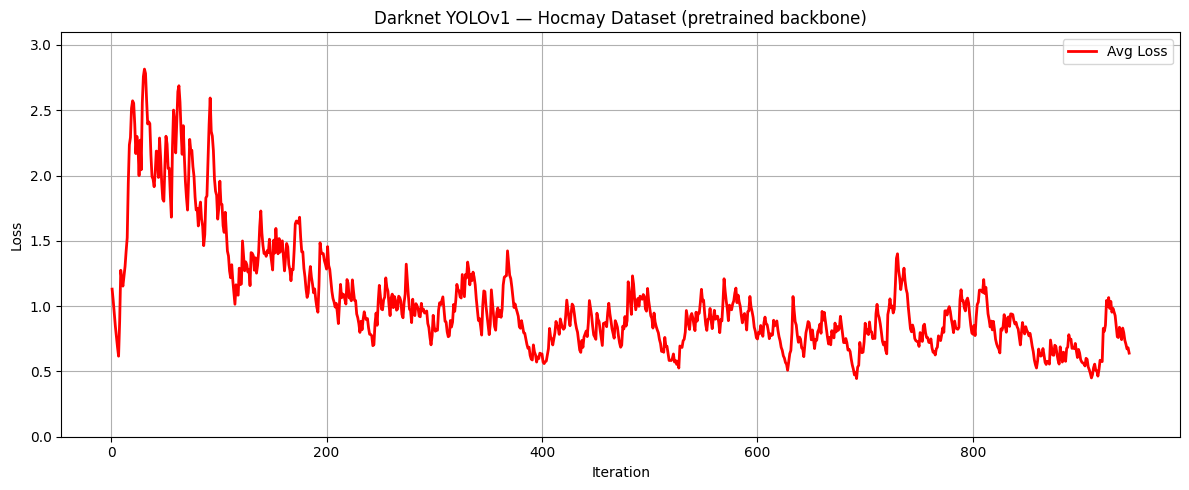

Final avg loss  : 0.6401
Total iterations: 945


In [8]:
import re, matplotlib.pyplot as plt

iterations, avg_losses = [], []
with open('training_log.txt') as f:
    for line in f:
        m = re.match(r'^(\d+): [\d.nan]+, ([\d.]+) avg', line)
        if m:
            it  = int(m.group(1))
            avg = float(m.group(2))
            if avg < 1000 and avg > 0:
                iterations.append(it)
                avg_losses.append(avg)

if iterations:
    plt.figure(figsize=(12, 5))
    plt.plot(iterations, avg_losses, color='red', linewidth=2, label='Avg Loss')
    plt.xlabel('Iteration'); plt.ylabel('Loss')
    plt.title('Darknet YOLOv1 — Hocmay Dataset (pretrained backbone)')
    plt.legend(); plt.grid(True)
    plt.ylim(0, min(50, max(avg_losses) * 1.1))
    plt.tight_layout()
    plt.savefig('darknet_loss.png', dpi=150)
    plt.show()
    print(f'Final avg loss  : {avg_losses[-1]:.4f}')
    print(f'Total iterations: {iterations[-1]}')
else:
    print('No log found — run training first')

## Evaluate mAP

In [9]:
%cd /content/darknet
import glob

weights = sorted(glob.glob('backup/*.weights'))
print('Available weights:', weights)

if weights:
    best = weights[-1]
    print(f'\nEvaluating: {best}')
    !./darknet detector map cfg/hocmay1-1.data cfg/yolov1.cfg {best}
else:
    print('No weights found — run training first!')

/content/darknet
Available weights: ['backup/yolov1_100.weights', 'backup/yolov1_200.weights', 'backup/yolov1_300.weights', 'backup/yolov1_400.weights', 'backup/yolov1_500.weights', 'backup/yolov1_600.weights', 'backup/yolov1_700.weights', 'backup/yolov1_800.weights', 'backup/yolov1_900.weights', 'backup/yolov1_final.weights']

Evaluating: backup/yolov1_final.weights


## Save to Google Drive

In [11]:
from google.colab import drive
import shutil, os

drive.mount('/content/drive', force_remount=True)

OUT = '/content/drive/MyDrive/Darknet_YOLOv1_Hocmay_Results'
os.makedirs(OUT, exist_ok=True)

if os.path.exists('backup'):
    shutil.copytree('backup', f'{OUT}/weights', dirs_exist_ok=True)

for fname in ['training_log.txt', 'darknet_loss.png']:
    if os.path.exists(fname):
        shutil.copy(fname, f'{OUT}/{fname}')

print(f'Saved to Drive: {OUT}')



Mounted at /content/drive
Saved to Drive: /content/drive/MyDrive/Darknet_YOLOv1_Hocmay_Results
